# Atividade 2
---
**Objetivo**

Aplicar técnicas de filtragem espacial para suavização, remoção de ruído e detecção de bordas
em imagens reais coletadas pelo próprio aluno, analisando criticamente o tipo de degradação
presente e justificando a escolha do filtro mais adequado com base nos fundamentos teóricos do
pré-processamento de imagens.

## Preparação do ambiente
---
utilzaremos as bibliotecas
- opencv
- matplotlib

In [1]:
import cv2
import matplotlib.pyplot as plt
import os
import numpy as np

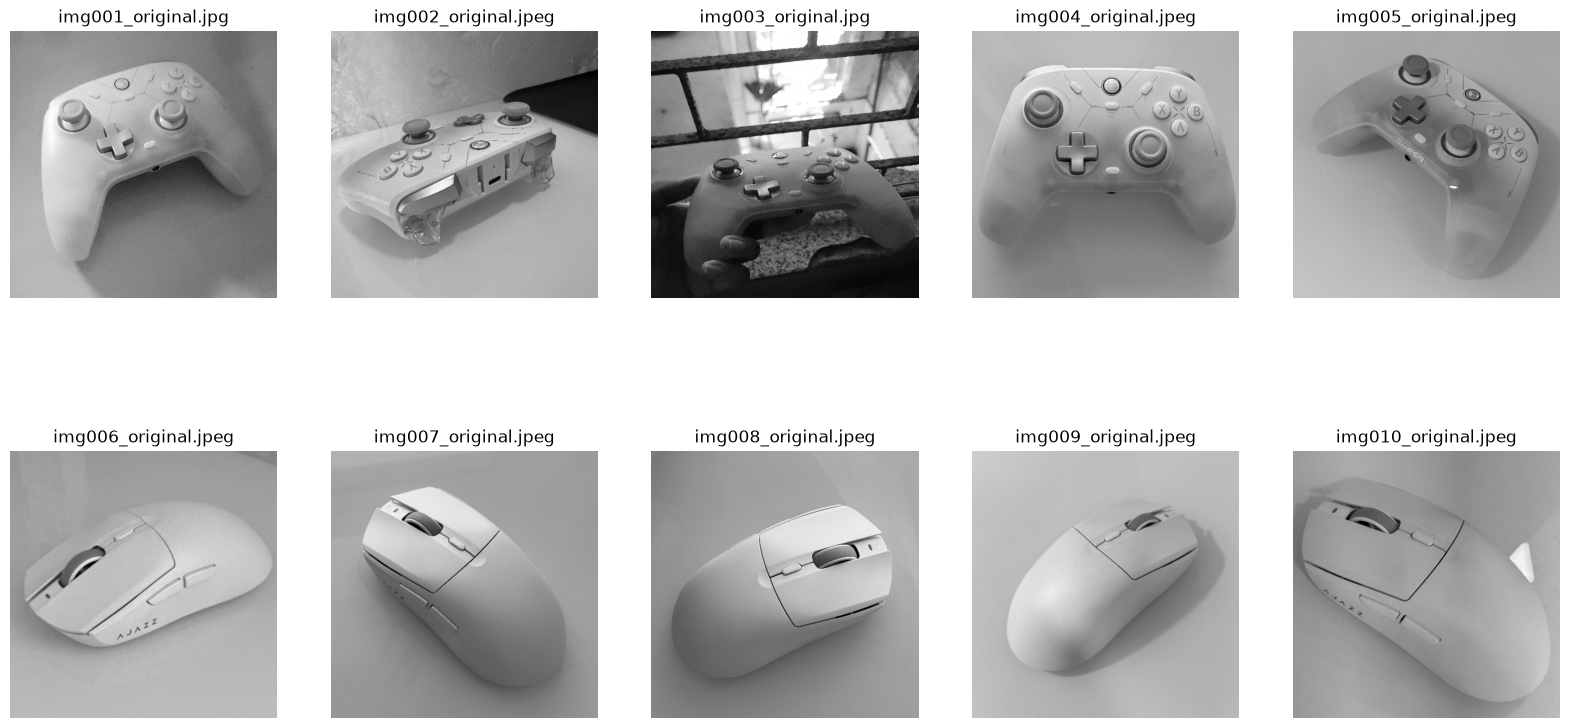

In [2]:
dir_A = "dataset/classe-A"
dir_B = "dataset/classe-B"

EXTENSOES = (".jpg", ".jpeg", ".png")

def listar_imagens(pasta):
    return sorted(f for f in os.listdir(pasta) if f.lower().endswith(EXTENSOES))

def carregar_imagem(pasta, nome_base, flags=cv2.IMREAD_GRAYSCALE):
    # procura pelo nome sem extensao (ex.: "img001_original"), aceitando .jpg, .jpeg ou .png
    for f in listar_imagens(pasta):
        if os.path.splitext(f)[0] == nome_base:
            return cv2.imread(os.path.join(pasta, f), flags)
    raise FileNotFoundError(f"{nome_base} nao encontrada em {pasta}")

images_class_A = listar_imagens(dir_A)
images_class_B = listar_imagens(dir_B)

fig, axs = plt.subplots(2, 5, figsize=(20, 10))
for idx, name in enumerate(images_class_A):
    img = cv2.imread(os.path.join(dir_A, name), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (512, 512))
    axs[0][idx].imshow(img, cmap="gray")
    axs[0][idx].set_title(name)
    axs[0][idx].axis("off")

for idx, name in enumerate(images_class_B):
    img = cv2.imread(os.path.join(dir_B, name), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (512, 512))
    axs[1][idx].imshow(img, cmap="gray")
    axs[1][idx].set_title(name)
    axs[1][idx].axis("off")


## Parte 1: Selecao de Imagens
---
**Criterios**: imagens que apresentam pelo menos uma das caracteristicas abaixo
- Granulacao
- Pequenas variacoes aleatorias de intensidade
- Baixa qualidade visual
- Compressao visivel
- Pequeno nivel de ruido

**Como as imagens foram comparadas**: todas foram convertidas para tons de cinza e padronizadas em 1024x1024 (recorte quadrado central + `INTER_AREA`), ja que as resolucoes originais vao de 1816 ate 4160 px. O nivel de ruido (`ruido ROI`) e o desvio-padrao do residuo passa-alta (imagem - imagem suavizada com sigma=2) medido apenas nas regioes planas, isto e, a metade dos blocos 16x16 com menor gradiente (sem bordas e ignorando areas escuras ou estouradas, onde o ruido fica escondido). A `curtose` desse residuo e um indicio do tipo de ruido: ~3 e ruido gaussiano e valores bem acima de 3 indicam caudas pesadas (pixels muito discrepantes, parecido com ruido impulsivo). Ela e so um indicio, pois pode captar estrutura residual que escapou da regiao plana (por isso aparece alta ate em imagens de pouco ruido, como img004).

As imagens escolhidas foram as duas de maior ruido de cada classe (tabela da celula abaixo). Classe A = controle de videogame, classe B = mouse.

| Imagem | Classe | Tipo de degradacao observada | Hipotese sobre a origem do ruido |
|---|---|---|---|
| img001_original | A | **Granulacao** fina e pequenas variacoes aleatorias de intensidade em superficies lisas (ruido ROI = 2,99; curtose 4,6) | ISO 3200 a 1/250 s (EXIF): a pouca luz do ambiente obrigou o celular a amplificar o sinal do sensor, e o ruido de sensor amplificado ainda passou por compressao JPEG |
| img003_original | A | **Maior nivel de ruido do dataset** (ruido ROI = 3,19; curtose 6,5) e alto contraste (variancia 4803) | Foto contra a luz (janela ao fundo), ISO 3200 a 1/3000 s: o controle fica subexposto e o processamento do celular clareia as sombras, amplificando o ruido nelas |
| img006_original | B | **Pequeno nivel de ruido** (ruido ROI = 1,36) e **baixa qualidade visual**: baixo contraste (variancia 165, a menor do dataset) | Foto contra o sol: o mouse fica na sombra e quase sem diferenca de tom para o fundo; ruido de sensor e compressao JPEG ficam visiveis nessa faixa estreita de intensidades |
| img010_original | B | **Pequenas variacoes aleatorias de intensidade** (ruido ROI = 1,13) sobre superficie fosca | Vidro da mesa refletindo a luz do sol (iluminacao irregular) somado a textura do plastico e a compressao JPEG |

As hipoteses de img001 e img003 sao apoiadas pelo EXIF (ISO 3200). As fotos da classe B nao tem EXIF, entao as hipoteses delas vem da observacao das condicoes de captura.


In [3]:
from PIL import Image

TAM = 1024  # lado (em pixels) das imagens usadas na analise
plt.rcParams["figure.dpi"] = 65

def preparar(img, tam=TAM):
    # recorte quadrado central (nao distorce a proporcao) + reducao com INTER_AREA (sem aliasing)
    h, w = img.shape
    l = min(h, w)
    y0, x0 = (h - l) // 2, (w - l) // 2
    return cv2.resize(img[y0:y0 + l, x0:x0 + l], (tam, tam), interpolation=cv2.INTER_AREA)

def gradiente(img):
    # Sobel 3x3 normalizado (/8): o resultado fica em "niveis de cinza por pixel"
    f = img.astype(np.float32)
    gx = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3) / 8
    gy = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3) / 8
    return gx, gy, np.hypot(gx, gy)

def mapear_regioes(img, bloco=16, pct_plano=50, pct_borda=97):
    # Localiza, numa copia suavizada (sigma=2), as regioes planas (sem estrutura) e as bordas reais.
    # O ruido e as bordas sao medidos sempre nessas MESMAS regioes, antes e depois de filtrar.
    ref = cv2.GaussianBlur(img, (0, 0), 2)
    mag = gradiente(ref)[2]
    n = img.shape[0] // bloco
    por_bloco = lambda a: a[:n * bloco, :n * bloco].reshape(n, bloco, n, bloco).mean(axis=(1, 3))
    mag_b, lum_b = por_bloco(mag), por_bloco(ref.astype(np.float32))
    valido = (lum_b > 25) & (lum_b < 235)  # ignora areas escuras/estouradas (o ruido fica escondido)
    plano_b = valido & (mag_b <= np.percentile(mag_b[valido], pct_plano))
    plano = np.kron(plano_b.astype(np.uint8), np.ones((bloco, bloco), np.uint8)).astype(bool)
    borda = mag >= np.percentile(mag, pct_borda)
    return plano, borda

def ruido_roi(img, plano):
    # desvio-padrao do residuo passa-alta (img - suavizada) dentro das regioes planas
    f = img.astype(np.float32)
    return (f - cv2.GaussianBlur(f, (0, 0), 2))[plano].std()

def curtose_roi(img, plano):
    # ~3 = ruido gaussiano; bem acima de 3 = caudas pesadas (pixels muito discrepantes, parecido com ruido impulsivo)
    f = img.astype(np.float32)
    r = (f - cv2.GaussianBlur(f, (0, 0), 2))[plano]
    return ((r - r.mean()) ** 4).mean() / r.var() ** 2

def exif(caminho):
    sub = Image.open(caminho).getexif().get_ifd(0x8769)
    return sub.get(0x8827), sub.get(0x829A)  # ISO, tempo de exposicao (s)

In [4]:
print(f"{'imagem':26s}{'ISO':>6s}{'exposicao':>11s}{'media':>8s}{'variancia':>11s}{'ruido ROI':>11s}{'curtose':>9s}")
for pasta, lista in ((dir_A, images_class_A), (dir_B, images_class_B)):
    for nome in lista:
        img = preparar(cv2.imread(os.path.join(pasta, nome), cv2.IMREAD_GRAYSCALE))
        plano, _ = mapear_regioes(img)
        iso, exp = exif(os.path.join(pasta, nome))
        exp = f"1/{round(1 / float(exp))}s" if exp else "-"
        print(f"{nome:26s}{str(iso or '-'):>6s}{exp:>11s}{img.mean():8.1f}{img.var():11.1f}{ruido_roi(img, plano):11.2f}{curtose_roi(img, plano):9.2f}")
    print()

imagem                       ISO  exposicao   media  variancia  ruido ROI  curtose
img001_original.jpg         3200     1/250s   142.2     1565.9       2.99     4.60


img002_original.jpeg           -          -   151.4     2063.3       1.65     9.87
img003_original.jpg         3200    1/3000s   110.6     4803.2       3.19     6.51


img004_original.jpeg           -          -   150.3     1218.8       1.00    19.25


img005_original.jpeg           -          -   151.9      758.8       0.87     3.56

img006_original.jpeg           -          -   104.1      165.2       1.36     3.04


img007_original.jpeg           -          -   149.5     1008.4       0.98     4.05
img008_original.jpeg           -          -   152.3     1182.4       1.11     4.60


img009_original.jpeg           -          -   156.3      515.2       0.87     3.22
img010_original.jpeg           -          -   153.4      395.8       1.13     3.47



## Parte 2: Aplicacao de filtros de suavizacao
---

**Metodo**: Aplicar os seguintes filtros com os respectivos parametros para cada imagem
- Filtro Medio
    - Kernel 3x3
    - Kernel 5x5
- Filtro Gaussiano
    - 𝜎 = 1
    - 𝜎 = 3
- Filtro da Mediana
    - Kernel 3x3
    - Kernel 5x5

**Metricas usadas para comparar os filtros** (nas mesmas regioes da imagem original, antes e depois de filtrar):
- `media` e `variancia` dos niveis de cinza da imagem inteira
- `ruido ROI`: desvio-padrao do residuo passa-alta nas regioes planas (mesma definicao da Parte 1). `ruido removido` = queda percentual desse valor
- `bordas retidas`: gradiente medio (Sobel) nas bordas reais, relativo ao da imagem original. Mede quanto o filtro borrou as bordas (100% = nada mudou)

Para cada imagem sao mostradas a imagem inteira e um zoom de 160x160 px (pixels sem interpolacao) na regiao com mais bordas, onde o efeito de cada filtro fica visivel.

In [5]:
def aplicar_filtros(img, titulo):
    filtros = {
        "original": img,
        "filtro medio 3x3": cv2.blur(img, ksize=(3, 3)),
        "filtro medio 5x5": cv2.blur(img, ksize=(5, 5)),
        "filtro gaussiano sigma 1": cv2.GaussianBlur(img, ksize=(0, 0), sigmaX=1),
        "filtro gaussiano sigma 3": cv2.GaussianBlur(img, ksize=(0, 0), sigmaX=3),
        "filtro mediana 3x3": cv2.medianBlur(img, ksize=3),
        "filtro mediana 5x5": cv2.medianBlur(img, ksize=5)
    }

    # imagem inteira
    fig, axs = plt.subplots(3, 2, figsize=(12, 12), constrained_layout=True)
    fig.suptitle(titulo)
    for ax, (nome, im) in zip(axs.flat, list(filtros.items())[1:]):
        ax.set_title(nome)
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.axis("off")

    # zoom (160x160 px, pixels sem interpolacao) na janela com mais bordas, onde ruido e bordas aparecem juntos
    densidade = cv2.blur(mapear_regioes(img)[1].astype(np.float32), (160, 160))
    y, x = np.unravel_index(densidade.argmax(), densidade.shape)
    y, x = np.clip(y - 80, 0, TAM - 160), np.clip(x - 80, 0, TAM - 160)
    fig, axs = plt.subplots(2, 4, figsize=(14, 7.5), constrained_layout=True)
    fig.suptitle(f"{titulo} - zoom")
    for ax, (nome, im) in zip(axs.flat, filtros.items()):
        ax.set_title(nome)
        ax.imshow(im[y:y + 160, x:x + 160], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.axis("off")
    axs.flat[-1].axis("off")
    plt.show()

    return filtros

In [6]:
selecionadas = {
    "img001_original": dir_A,  # classe A
    "img003_original": dir_A,  # classe A
    "img006_original": dir_B,  # classe B
    "img010_original": dir_B,  # classe B
}

imagens = {nome: preparar(carregar_imagem(pasta, nome)) for nome, pasta in selecionadas.items()}
filtros = {}

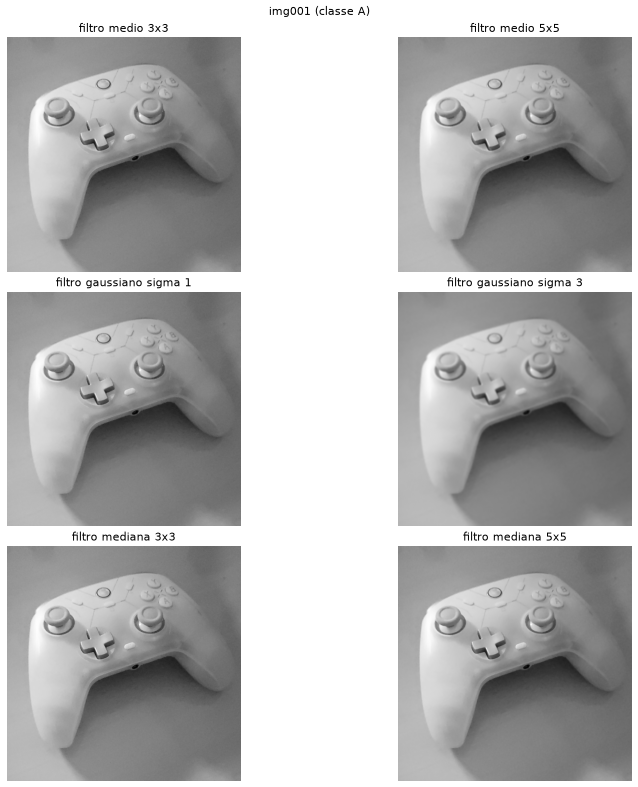

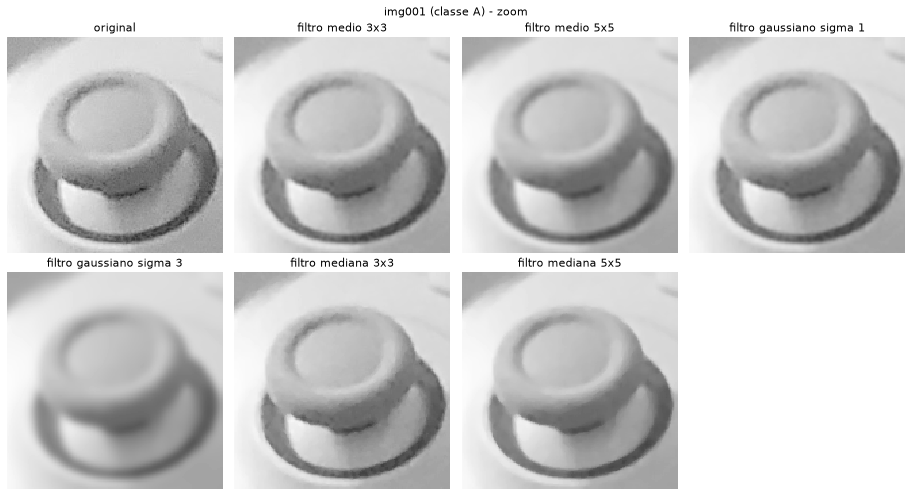

In [7]:
# img001 (classe A)

filtros["img001_original"] = aplicar_filtros(imagens["img001_original"], "img001 (classe A)")

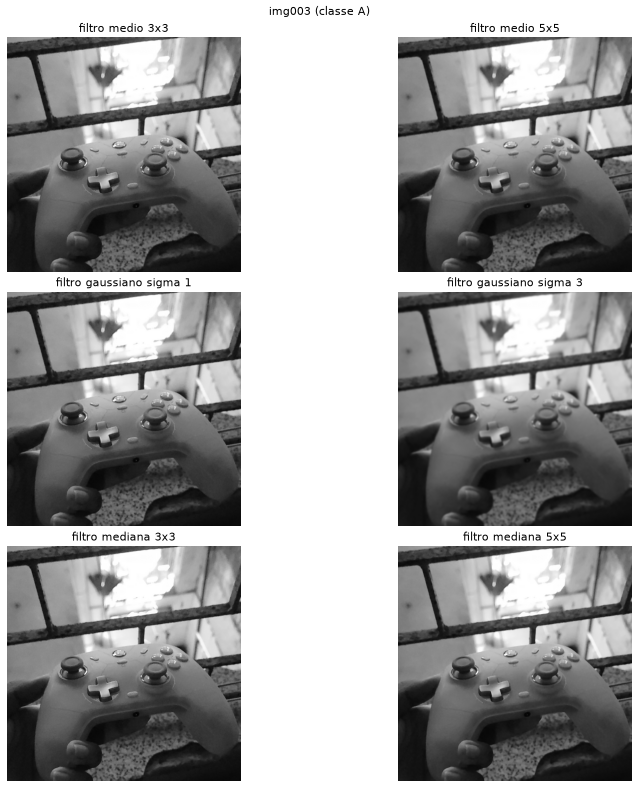

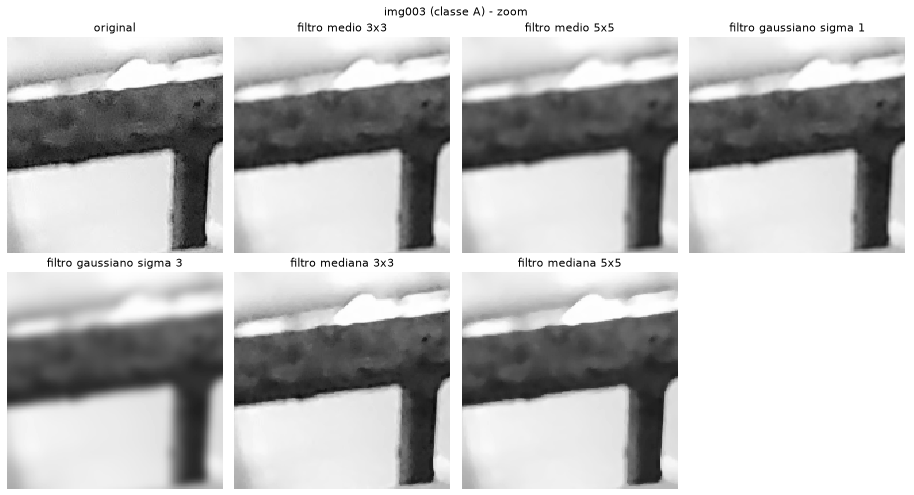

In [8]:
# img003 (classe A)

filtros["img003_original"] = aplicar_filtros(imagens["img003_original"], "img003 (classe A)")

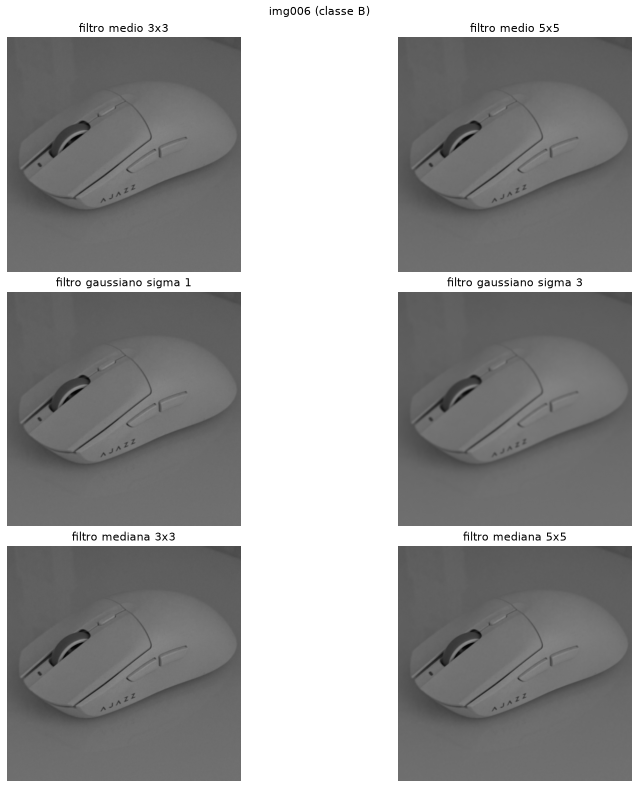

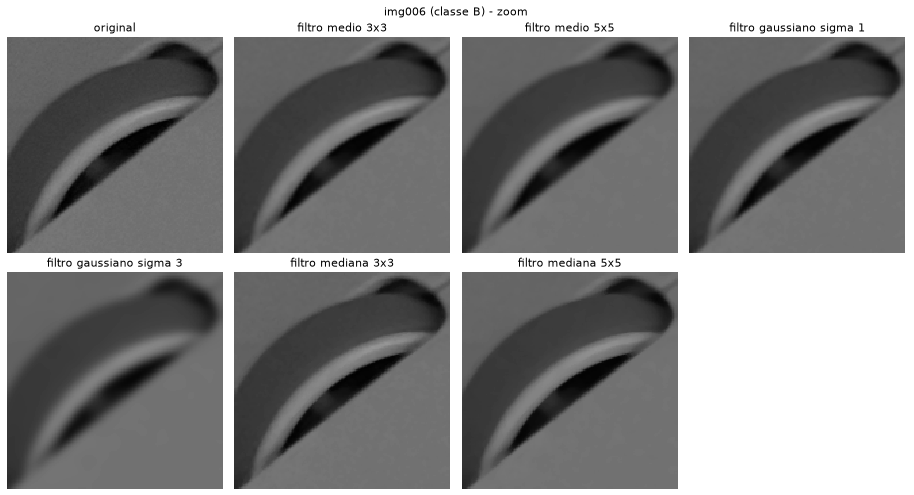

In [9]:
# img006 (classe B)

filtros["img006_original"] = aplicar_filtros(imagens["img006_original"], "img006 (classe B)")

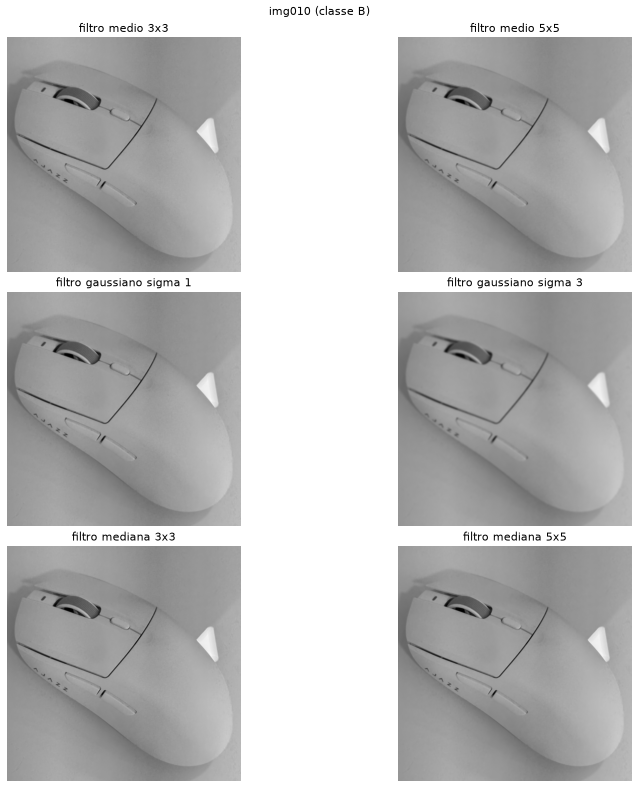

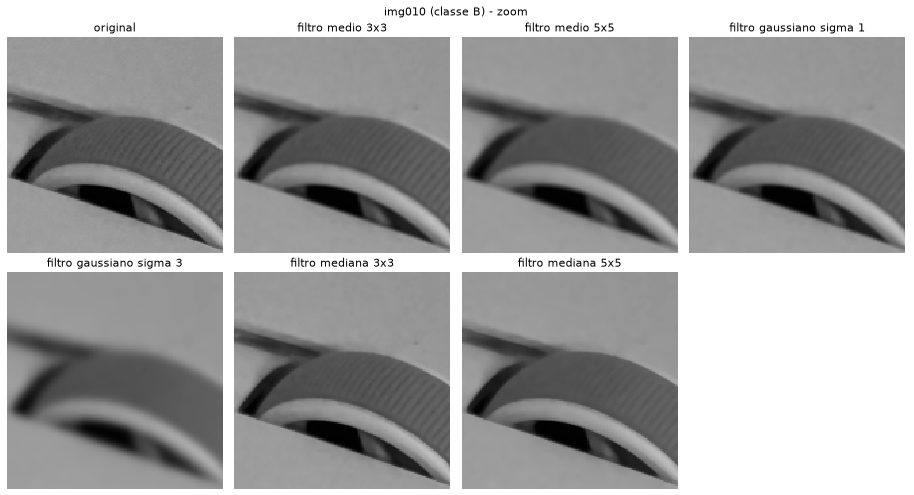

In [10]:
# img010 (classe B)

filtros["img010_original"] = aplicar_filtros(imagens["img010_original"], "img010 (classe B)")

In [11]:
def estatisticas(filtrados, plano, borda):
    # ruido removido: queda do desvio-padrao do residuo nas regioes planas
    # bordas retidas: gradiente medio nas bordas reais, relativo ao da imagem original
    g0 = gradiente(filtrados["original"])[2][borda].mean()
    r0 = ruido_roi(filtrados["original"], plano)
    resultado = {}
    print(f"{'filtro':26s}{'media':>8s}{'variancia':>11s}{'ruido ROI':>11s}{'ruido removido':>16s}{'bordas retidas':>16s}")
    for nome, im in filtrados.items():
        r, g = ruido_roi(im, plano), gradiente(im)[2][borda].mean()
        resultado[nome] = (100 * (1 - r / r0), 100 * g / g0)
        print(f"{nome:26s}{im.mean():8.1f}{im.var():11.1f}{r:11.2f}{resultado[nome][0]:15.1f}%{resultado[nome][1]:15.1f}%")
    return resultado

regioes = {nome: mapear_regioes(img) for nome, img in imagens.items()}

compromisso = {}
for nome in imagens:
    print(nome)
    compromisso[nome] = estatisticas(filtros[nome], *regioes[nome])
    print()

img001_original
filtro                       media  variancia  ruido ROI  ruido removido  bordas retidas
original                     142.2     1565.9       2.99            0.0%          100.0%
filtro medio 3x3             142.2     1548.6       0.97           67.5%           86.7%
filtro medio 5x5             142.2     1538.6       0.55           81.8%           75.3%
filtro gaussiano sigma 1     142.2     1545.9       0.80           73.2%           83.6%
filtro gaussiano sigma 3     142.2     1516.3       0.27           90.8%           50.3%


filtro mediana 3x3           142.3     1550.2       1.15           61.5%           89.5%
filtro mediana 5x5           142.4     1543.8       0.63           78.9%           80.5%

img003_original
filtro                       media  variancia  ruido ROI  ruido removido  bordas retidas
original                     110.6     4803.2       3.19            0.0%          100.0%
filtro medio 3x3             110.6     4758.3       1.25           60.8%           89.6%
filtro medio 5x5             110.6     4716.9       0.81           74.7%           77.6%


filtro gaussiano sigma 1     110.6     4747.5       1.08           66.0%           86.7%
filtro gaussiano sigma 3     110.6     4605.8       0.48           84.8%           52.4%
filtro mediana 3x3           110.7     4777.5       1.43           55.3%           94.0%
filtro mediana 5x5           110.7     4760.5       0.90           71.7%           87.6%

img006_original
filtro                       media  variancia  ruido ROI  ruido removido  bordas retidas
original                     104.1      165.2       1.36            0.0%          100.0%


filtro medio 3x3             104.1      161.0       0.61           55.0%           93.6%
filtro medio 5x5             104.1      156.9       0.36           73.2%           84.4%
filtro gaussiano sigma 1     104.1      159.9       0.54           60.2%           91.3%
filtro gaussiano sigma 3     104.1      146.1       0.20           85.4%           58.3%
filtro mediana 3x3           104.1      162.9       0.68           49.6%           96.6%
filtro mediana 5x5           104.1      160.6       0.40           70.6%           90.8%

img010_original


filtro                       media  variancia  ruido ROI  ruido removido  bordas retidas
original                     153.4      395.8       1.13            0.0%          100.0%
filtro medio 3x3             153.4      385.2       0.54           52.5%           92.1%
filtro medio 5x5             153.4      373.8       0.37           67.3%           81.2%
filtro gaussiano sigma 1     153.4      382.1       0.49           57.0%           89.1%


filtro gaussiano sigma 3     153.4      348.8       0.25           77.7%           52.3%
filtro mediana 3x3           153.5      392.1       0.58           48.5%           96.2%
filtro mediana 5x5           153.5      386.7       0.39           65.4%           90.0%



filtro                      ruido removido  bordas retidas
filtro medio 3x3                     59.0%           90.5%
filtro medio 5x5                     74.3%           79.6%
filtro gaussiano sigma 1             64.1%           87.7%
filtro gaussiano sigma 3             84.7%           53.3%
filtro mediana 3x3                   53.7%           94.1%
filtro mediana 5x5                   71.7%           87.2%


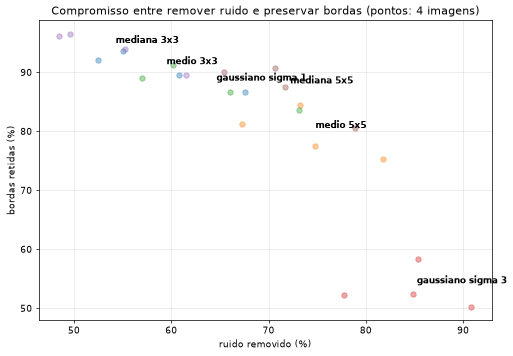

In [12]:
# media das 4 imagens + grafico ruido removido x bordas retidas (quanto mais no canto superior direito, melhor)
nomes_filtros = list(filtros["img001_original"])[1:]
media = {f: np.mean([compromisso[n][f] for n in imagens], axis=0) for f in nomes_filtros}

print(f"{'filtro':26s}{'ruido removido':>16s}{'bordas retidas':>16s}")
for f, (removido, retido) in media.items():
    print(f"{f:26s}{removido:15.1f}%{retido:15.1f}%")

fig, ax = plt.subplots(figsize=(9, 6))
for f in nomes_filtros:
    xs, ys = zip(*(compromisso[n][f] for n in imagens))
    ax.scatter(xs, ys, alpha=0.4)
    ax.annotate(f.replace("filtro ", ""), media[f], xytext=(6, 6), textcoords="offset points", fontsize=10, weight="bold")
ax.set_xlabel("ruido removido (%)")
ax.set_ylabel("bordas retidas (%)")
ax.set_title("Compromisso entre remover ruido e preservar bordas (pontos: 4 imagens)")
ax.grid(alpha=0.3)
plt.show()

### Analise da Parte 2

Media das 4 imagens (a ordem de ruido removido entre os filtros e a mesma nas 4 imagens):

| Filtro | Ruido removido | Bordas retidas |
|---|---|---|
| Media 3x3 | 59,0% | 90,5% |
| Media 5x5 | 74,3% | 79,6% |
| Gaussiano sigma=1 | 64,1% | 87,7% |
| Gaussiano sigma=3 | 84,7% | 53,3% |
| Mediana 3x3 | 53,7% | 94,1% |
| Mediana 5x5 | 71,7% | 87,2% |

**Qual filtro reduziu mais o ruido?** O **Gaussiano com sigma=3** (84,7% em media, de 77,7% a 90,8% conforme a imagem), seguido da media 5x5 (74,3%) e da mediana 5x5 (71,7%). Em todas as familias, aumentar o kernel (ou o sigma) remove mais ruido, como previsto no e-book (janela maior = suavizacao mais intensa). Mas o Gaussiano sigma=3 tem custo alto: o zoom mostra o botao e o contorno do controle visivelmente borrados, e so 53% do gradiente das bordas sobrevive.

**Qual preservou melhor as bordas?** A **mediana**: a 3x3 reteve 94,1% das bordas e a 5x5 reteve 87,2%. A comparacao mais limpa e entre a media 5x5 e a mediana 5x5, que usam a mesma janela: a mediana removeu quase o mesmo ruido (71,7% contra 74,3%) mas manteve 7,6 pontos percentuais a mais de borda (87,2% contra 79,6%). Isso confirma a Tabela 1 do e-book: a media e linear e trata todos os vizinhos igualmente, entao uma transicao abrupta vira uma rampa; a mediana e nao linear e escolhe um valor que existe na vizinhanca, entao um degrau continua sendo um degrau. O Gaussiano fica no meio (sigma=1: 87,7% de bordas), pois pondera mais o centro da janela do que a media.

**O que aconteceu com a variancia dos niveis de cinza?** A **media** quase nao muda (linear preserva a media; a mediana alterou ate +0,2 nivel de cinza), mas a **variancia global diminui em todos os filtros**, e quanto mais forte o filtro, maior a queda. Em img001 (1565,9) foi para 1543,8 com mediana 5x5 (-1,4%) e para 1516,3 com Gaussiano sigma=3 (-3,2%). A queda global e pequena nas imagens de alto contraste porque a variancia total e dominada pela estrutura da cena (o ruido de img001 tem variancia ~9, contra 1566 da imagem). Ja nas imagens de baixo contraste o efeito aparece: img006 caiu de 165,2 para 146,1 (-11,6%) e img010 de 395,8 para 348,8 (-11,9%) com sigma=3. Parte dessa queda e ruido removido, e parte e contraste real perdido (bordas e detalhes borrados). A variancia do ruido nas regioes planas (`ruido ROI` ao quadrado) cai de cerca de 73% a 99%, que e onde o filtro faz o que se espera.

**Tipo de ruido e escolha do filtro.** Pelo e-book, a mediana e indicada para ruido impulsivo e a media/Gaussiano para ruido gaussiano. Em img006 e img010 a curtose do ruido e ~3 (gaussiano), mas img001 e img003 tem caudas mais pesadas (curtose 4,6 e 6,5), o que e um indicio de pixels discrepantes (ISO 3200 e compressao), situacao em que a mediana e menos sensivel a outliers. Os numeros acima mostram que, na media das 4 imagens, a mediana 5x5 e o melhor compromisso: remove 71,7% do ruido preservando 87,2% das bordas, enquanto o Gaussiano sigma=1 removeu so 64,1% com 87,7% das bordas (7,6 pontos a menos de ruido removido para a mesma preservacao). A media 5x5 remove um pouco mais ruido (74,3%), mas perde 7,6 pontos de bordas, e o Gaussiano sigma=3 e destrutivo demais. **O filtro escolhido para a Parte 4 e a mediana 5x5.** Limitacao: a mediana tende a apagar estruturas finas (linhas mais estreitas que metade da janela) e arredondar cantos, o que a metrica `bordas retidas` (gradiente nas bordas mais fortes) nao mede bem. Se fosse preciso preservar detalhes finos, a mediana 3x3 seria a alternativa (94,1% das bordas, 53,7% do ruido).

## Parte 3: Deteccao de Bordas (sem suavizacao previa)
---

**Metodo**: aplicar diretamente na imagem original (sem filtrar) os operadores
- Sobel: gradiente em X, gradiente em Y e magnitude
- Prewitt: gradiente em X, gradiente em Y e magnitude
- Canny (`cv2.Canny`): testado com 3 pares de limiares (baixo, alto)

**Como comparar os operadores de forma justa**: os kernels de Sobel e Prewitt foram normalizados (divididos por 8 e por 6), entao o gradiente fica em "niveis de cinza por pixel" nos dois. Sobel e Prewitt so geram a magnitude; para contar bordas ela e binarizada com limiar T. O Canny trabalha com o gradiente sem normalizar (8x maior) e usa `L2gradient=True` (mesma magnitude sqrt(gx^2+gy^2)), entao cada limiar alto do Canny equivale a T = alto/8 no Sobel/Prewitt. Assim os tres operadores sao comparados em tres niveis de sensibilidade: **(20,60) / T=7,5** (mais sensivel), **(50,150) / T=18,8** e **(100,200) / T=25** (mais seletivo).

**Metricas** (calculadas nas mesmas regioes de referencia da Parte 2):
- `pixels de borda`: quantidade de bordas detectadas
- `bordas falsas (%)`: percentual dos pixels das regioes planas marcados como borda (ali nao existe estrutura real, entao qualquer borda e ruido)
- `cobertura (%)`: percentual das bordas reais (3% de maior gradiente da imagem suavizada) encontradas, com tolerancia de 2 px
- `comprimento medio`: pixels de borda por segmento conexo; quanto maior, mais continuas as bordas (e menos fragmentadas por ruido)

In [13]:
KX_PREWITT = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32) / 6  # /6 -> mesma escala do Sobel normalizado
KY_PREWITT = KX_PREWITT.T

# tres niveis de sensibilidade (limiar baixo, limiar alto) do Canny, do mais sensivel ao mais seletivo.
# Sobel e Prewitt sao binarizados com o limiar equivalente ao "alto" do Canny: o Canny trabalha com o gradiente
# sem normalizar (8x maior que o nosso), entao T = alto / 8 (L2gradient=True usa a mesma magnitude sqrt(gx^2+gy^2)).
LIMIARES = [(20, 60), (50, 150), (100, 200)]

def sobel(img):
    return gradiente(img)

def prewitt(img):
    f = img.astype(np.float32)
    gx = cv2.filter2D(f, cv2.CV_32F, KX_PREWITT)  # filter2D faz correlacao; o sinal muda mas a magnitude nao
    gy = cv2.filter2D(f, cv2.CV_32F, KY_PREWITT)
    return gx, gy, np.hypot(gx, gy)

def detectar_bordas(img):
    # mapas binarios de bordas: para cada nivel de sensibilidade, Sobel, Prewitt e Canny
    mapas = {}
    for baixo, alto in LIMIARES:
        t = alto / 8
        mapas[f"Sobel (T={t:.1f})"] = sobel(img)[2] > t
        mapas[f"Prewitt (T={t:.1f})"] = prewitt(img)[2] > t
        mapas[f"Canny ({baixo},{alto})"] = cv2.Canny(img, baixo, alto, L2gradient=True) > 0
    return mapas

def normalizar(a):
    return np.clip(a / np.percentile(a, 99.5), 0, 1)

def mostrar_bordas(img, titulo):
    fig, axs = plt.subplots(4, 3, figsize=(15, 20), constrained_layout=True)
    fig.suptitle(titulo)
    for linha, (nome, op) in enumerate((("Sobel", sobel), ("Prewitt", prewitt))):
        gx, gy, mag = op(img)
        for ax, (rotulo, a) in zip(axs[linha], (("Gradiente em X", np.abs(gx)), ("Gradiente em Y", np.abs(gy)), ("Magnitude", mag))):
            ax.set_title(f"{nome} - {rotulo}")
            ax.imshow(normalizar(a), cmap="gray")
            ax.axis("off")
    mapas = detectar_bordas(img)
    for ax, (baixo, alto) in zip(axs[2], LIMIARES):
        ax.set_title(f"Sobel binarizado (T={alto / 8:.1f})")
        ax.imshow(mapas[f"Sobel (T={alto / 8:.1f})"], cmap="gray")
        ax.axis("off")
    for ax, (baixo, alto) in zip(axs[3], LIMIARES):
        ax.set_title(f"Canny (limiar baixo={baixo}, alto={alto})")
        ax.imshow(mapas[f"Canny ({baixo},{alto})"], cmap="gray")
        ax.axis("off")
    plt.show()

def metricas_bordas(mapa, plano, borda):
    n = int(mapa.sum())
    falsas = 100 * mapa[plano].mean()  # % de pixels das regioes planas marcados como borda
    cobertura = 100 * cv2.dilate(mapa.astype(np.uint8), np.ones((5, 5), np.uint8))[borda].mean()  # % das bordas reais encontradas (tolerancia de 2 px)
    n_segmentos = cv2.connectedComponents(mapa.astype(np.uint8), connectivity=8)[0] - 1
    return n, falsas, cobertura, n / max(n_segmentos, 1)

def tabela_bordas(mapas, plano, borda):
    print(f"{'operador':18s}{'pixels de borda':>17s}{'bordas falsas (%)':>19s}{'cobertura (%)':>15s}{'comprimento medio':>19s}")
    for nome, mapa in mapas.items():
        n, falsas, cobertura, comp = metricas_bordas(mapa, plano, borda)
        print(f"{nome:18s}{n:17d}{falsas:19.2f}{cobertura:15.1f}{comp:19.1f}")

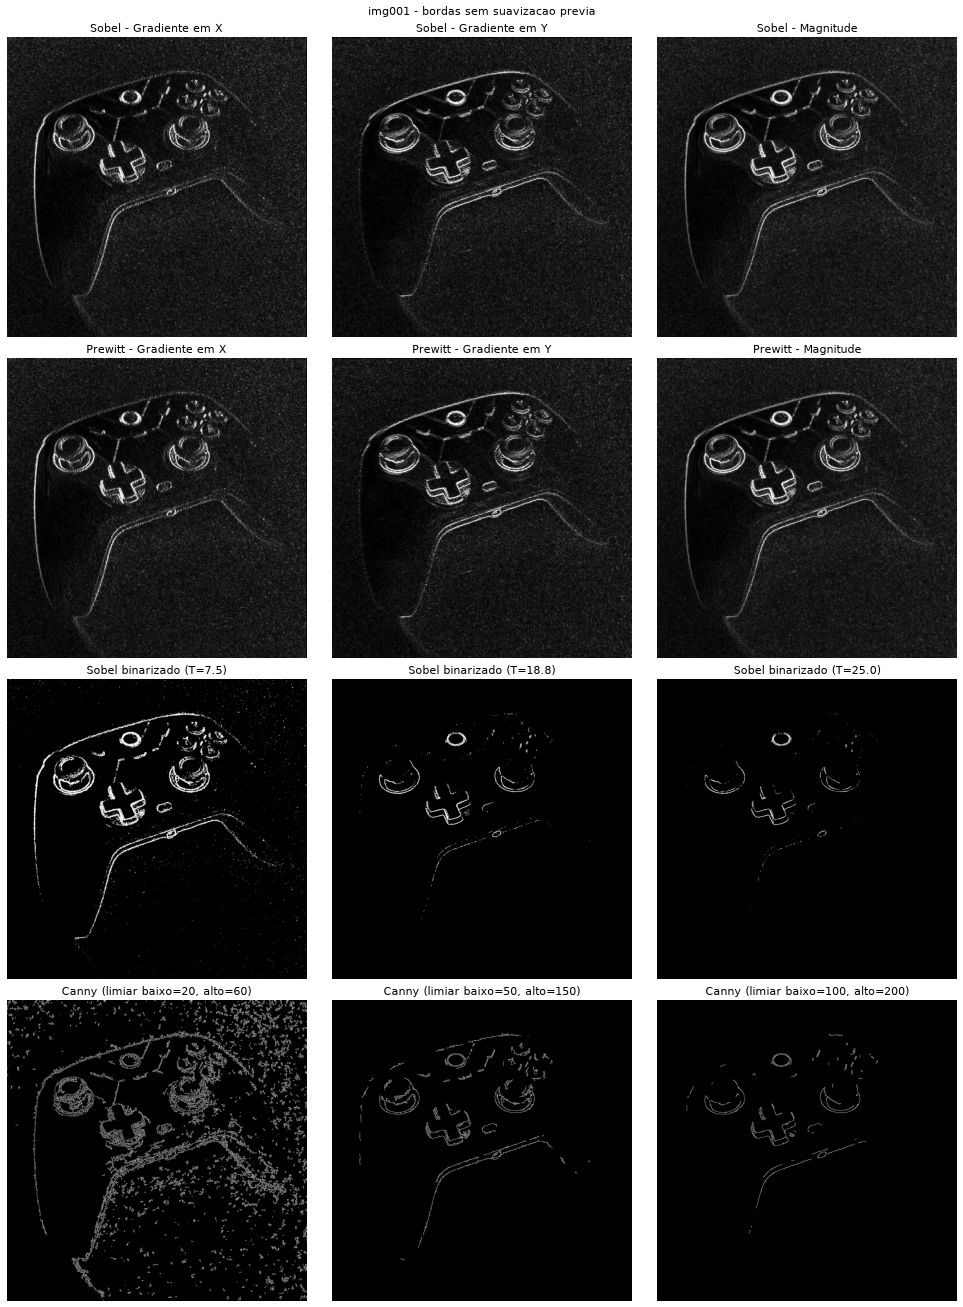

img001_original
operador            pixels de borda  bordas falsas (%)  cobertura (%)  comprimento medio
Sobel (T=7.5)                 31686               0.13           99.9               13.3
Prewitt (T=7.5)               29848               0.07           99.9               16.9
Canny (20,60)                 57242               1.63           98.3               29.6
Sobel (T=18.8)                 6756               0.00           61.6               23.4
Prewitt (T=18.8)               6608               0.00           60.3               23.2
Canny (50,150)                 9225               0.00           80.7               67.3
Sobel (T=25.0)                 3932               0.00           45.4               18.3
Prewitt (T=25.0)               3801               0.00           43.7               18.9
Canny (100,200)                4533               0.00           56.5               48.7



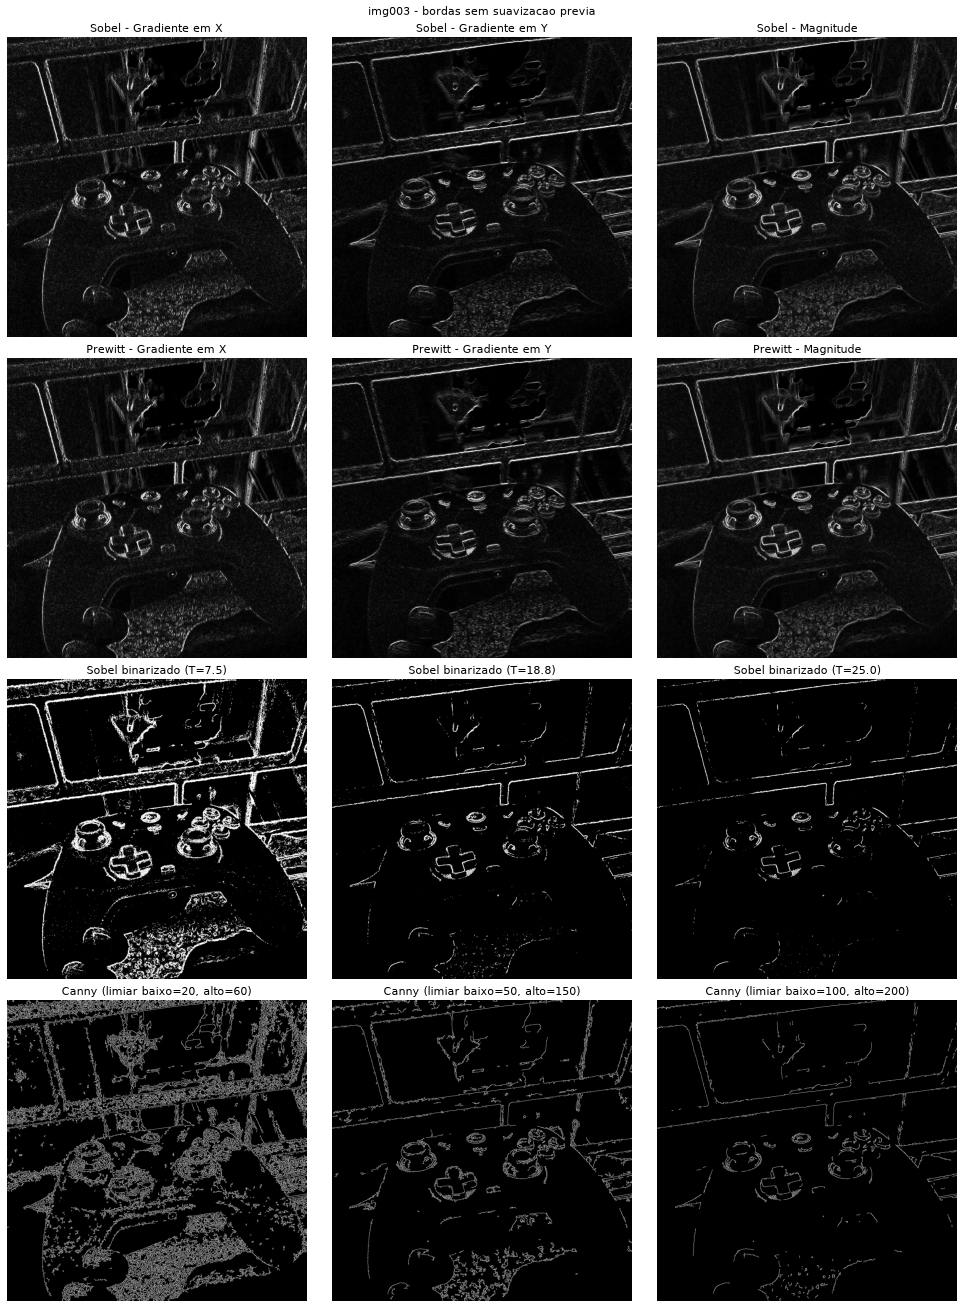

img003_original
operador            pixels de borda  bordas falsas (%)  cobertura (%)  comprimento medio
Sobel (T=7.5)                113101               0.61          100.0               23.4
Prewitt (T=7.5)              109195               0.50          100.0               23.9
Canny (20,60)                128910               4.63           98.1               36.5
Sobel (T=18.8)                27508               0.02           99.7               23.8
Prewitt (T=18.8)              26879               0.01           99.7               25.1
Canny (50,150)                34949               0.07           96.4               48.5
Sobel (T=25.0)                16978               0.01           95.9               23.4
Prewitt (T=25.0)              16577               0.01           95.4               24.0
Canny (100,200)               16357               0.02           94.8               37.4



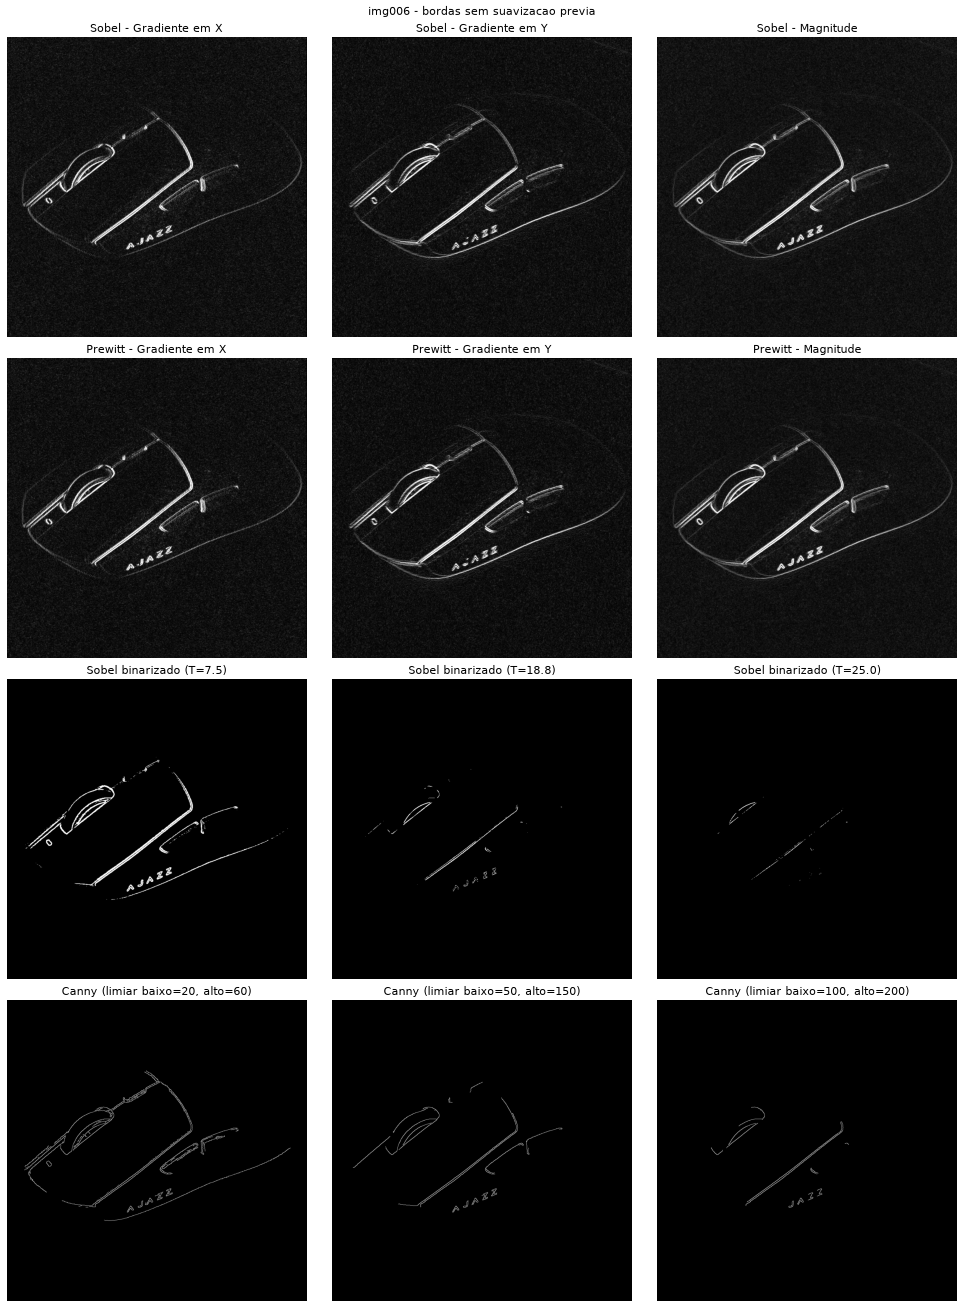

img006_original
operador            pixels de borda  bordas falsas (%)  cobertura (%)  comprimento medio
Sobel (T=7.5)                 14202               0.00           86.7              118.3
Prewitt (T=7.5)               14159               0.00           86.0              125.3
Canny (20,60)                  7698               0.00           84.1               68.7
Sobel (T=18.8)                 2620               0.00           30.3               31.6
Prewitt (T=18.8)               2527               0.00           29.4               32.8
Canny (50,150)                 3921               0.00           51.2              245.1
Sobel (T=25.0)                  802               0.00           14.1               12.9
Prewitt (T=25.0)                701               0.00           12.7               12.1
Canny (100,200)                2250               0.00           31.1              150.0



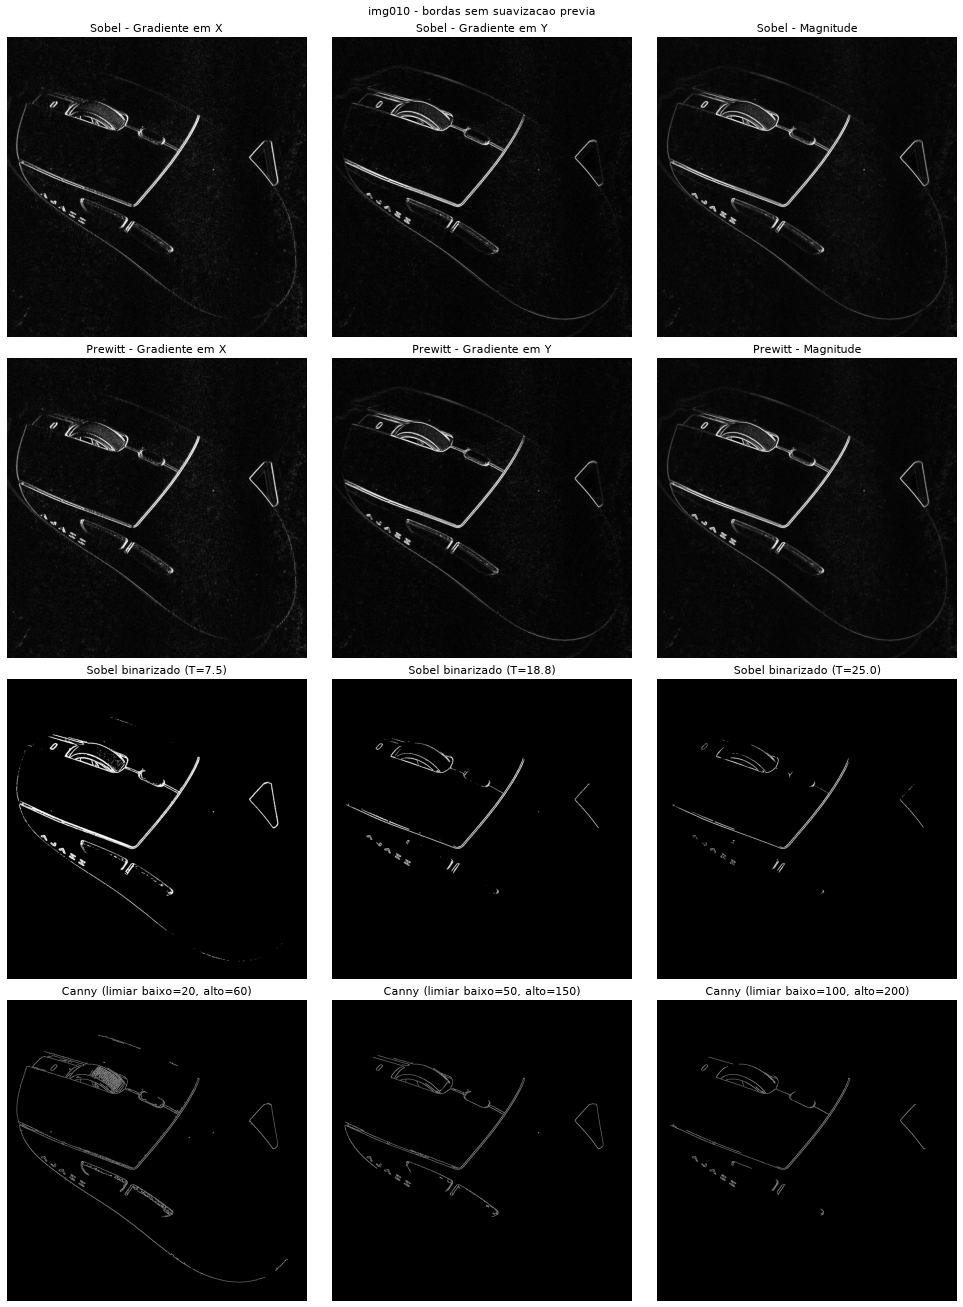

img010_original
operador            pixels de borda  bordas falsas (%)  cobertura (%)  comprimento medio
Sobel (T=7.5)                 19672               0.00           98.5               92.4
Prewitt (T=7.5)               19706               0.00           98.4              108.3
Canny (20,60)                 11844               0.00           91.6               79.0
Sobel (T=18.8)                 7497               0.00           66.8              122.9
Prewitt (T=18.8)               7607               0.00           66.2              143.5
Canny (50,150)                 6446               0.00           79.1              189.6
Sobel (T=25.0)                 5224               0.00           55.9               61.5
Prewitt (T=25.0)               5242               0.00           54.9               60.3
Canny (100,200)                4452               0.00           62.2              185.5



In [14]:
bordas_originais = {nome: detectar_bordas(img) for nome, img in imagens.items()}

for nome, img in imagens.items():
    mostrar_bordas(img, f"{nome[:6]} - bordas sem suavizacao previa")
    print(nome)
    tabela_bordas(bordas_originais[nome], *regioes[nome])
    print()

### Analise da Parte 3

**Presenca de bordas falsas e sensibilidade ao ruido.** Nas imagens mais ruidosas (img001 e img003, ISO 3200) o nivel de sensibilidade importa mais do que o operador:
- No nivel mais sensivel, o **Canny (20,60)** foi o mais afetado: 1,63% (img001) e 4,63% (img003) das regioes planas viraram borda, contra 0,13% e 0,61% do Sobel e 0,07% e 0,50% do Prewitt (T=7,5). Visualmente, na img003 o Canny (20,60) cobre quase toda a imagem de segmentos de ruido e da textura do fundo. A causa e que o limiar baixo (20 -> ~2,5 niveis de cinza por pixel) e da mesma ordem de grandeza do gradiente gerado pelo proprio ruido (desvio de ~3 niveis de cinza por pixel), e a explicacao mais provavel e que a histerese conecta esses fragmentos de ruido a bordas fortes. Alem disso, o `cv2.Canny` **nao inclui a suavizacao gaussiana** descrita na etapa 1 do e-book, entao sem filtrar antes ele fica exposto ao ruido.
- Nos niveis (50,150) e (100,200) o Canny e o Sobel/Prewitt ficam proximos de zero falsas bordas nas quatro imagens (no maximo 0,07%, em img003).
- Em img006 e img010 (ruido ~1,1 a 1,4) nao houve borda falsa em nenhum operador ou limiar.

**Sobel x Prewitt.** Em todas as imagens os dois ficaram praticamente iguais (pixels de borda diferem em ate ~6%, cobertura em menos de 2 pontos). O Prewitt teve ate um pouco menos de bordas falsas que o Sobel nas imagens ruidosas (0,07% contra 0,13% em img001), o oposto do que o e-book afirma (Sobel "ligeiramente mais robusto"). Como a diferenca e de centesimos de ponto percentual, a conclusao honesta e que, com os kernels normalizados, os dois sao equivalentes neste dataset; a vantagem teorica do Sobel (peso 2 no centro, que suaviza um pouco mais) nao aparece de forma mensuravel.

**Comparacao visual e estrutural.** Sobel e Prewitt produzem bordas **grossas e fragmentadas** (comprimento medio de 23 px no nivel T=18,8 de img001), pois marcam todos os pixels onde o gradiente passa do limiar. O Canny, pela supressao de nao-maximos, gera bordas de 1 pixel e, pela histerese, segmentos bem mais longos (67 px em img001 no nivel (50,150); 245 px em img006). A histerese tambem recupera bordas fracas ligadas a bordas fortes: com a mesma sensibilidade, o Canny (50,150) encontrou 80,7% das bordas reais de img001 contra 61,6% do Sobel (T=18,8).

**Limiar e contraste.** Aumentar o limiar elimina o ruido mas tambem as bordas reais: a cobertura do Sobel em img001 cai de 99,9% (T=7,5) para 45,4% (T=25). Em img006, a imagem de menor contraste, o Sobel com T=18,8 so acha 30,3% das bordas reais, ou seja, o limiar precisa ser adaptado ao contraste de cada imagem.

## Parte 4: Deteccao de Bordas apos Suavizacao
---

**Filtro escolhido: mediana 5x5** (justificativa na analise da Parte 2: melhor compromisso entre ruido removido, 71,7%, e bordas preservadas, 87,2%, alem de menor sensibilidade a pixels discrepantes). Foi aplicado a cada imagem e os mesmos operadores, limiares e metricas da Parte 3 foram reaplicados, de modo que antes e depois sao diretamente comparaveis. As regioes planas e as bordas reais de referencia sao as da imagem original.

In [15]:
FILTRO_ESCOLHIDO = "filtro mediana 5x5"

suavizadas = {nome: filtros[nome][FILTRO_ESCOLHIDO] for nome in imagens}
bordas_suavizadas = {nome: detectar_bordas(img) for nome, img in suavizadas.items()}

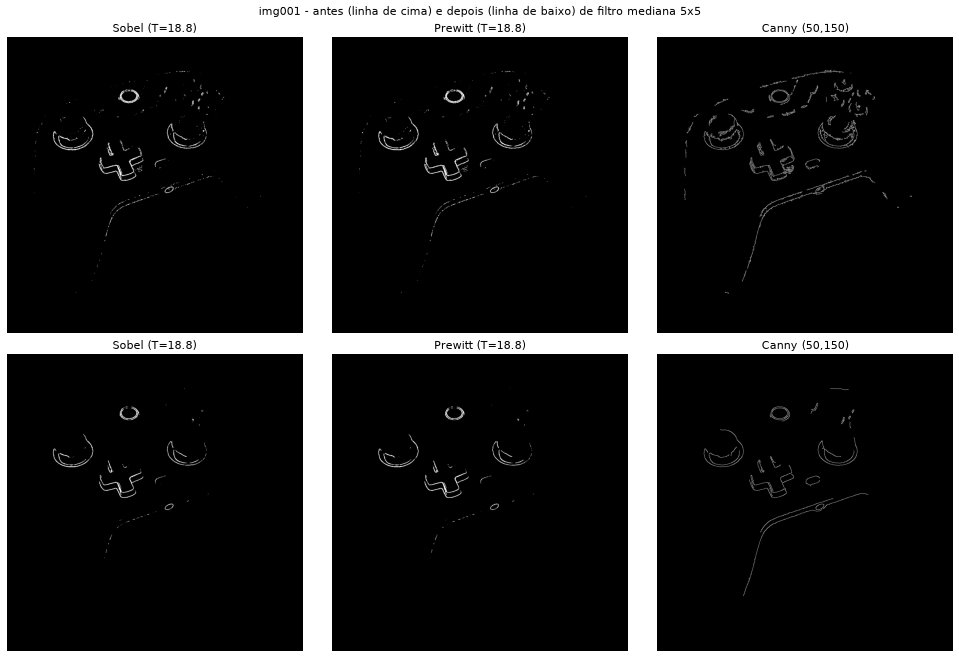

img001_original
operador                      pixels de borda  bordas falsas (%)  cobertura (%)  comprimento medio
Sobel (T=7.5)     original              31686               0.13           99.9               13.3
Sobel (T=7.5)     suavizada             18343               0.00           98.4               90.4
Prewitt (T=7.5)   original              29848               0.07           99.9               16.9
Prewitt (T=7.5)   suavizada             18376               0.00           98.3               92.8
Canny (20,60)     original              57242               1.63           98.3               29.6
Canny (20,60)     suavizada             11131               0.00           95.9               53.3
Sobel (T=18.8)    original               6756               0.00           61.6               23.4
Sobel (T=18.8)    suavizada              4274               0.00           42.5               56.2
Prewitt (T=18.8)  original               6608               0.00           60.3              

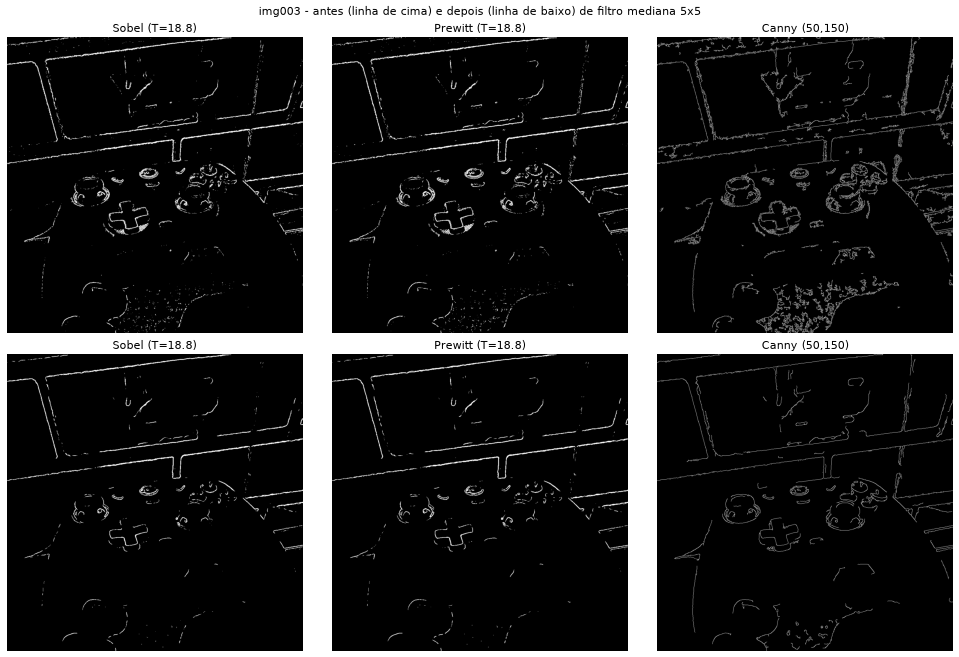

img003_original
operador                      pixels de borda  bordas falsas (%)  cobertura (%)  comprimento medio
Sobel (T=7.5)     original             113101               0.61          100.0               23.4
Sobel (T=7.5)     suavizada             67921               0.06          100.0               77.2
Prewitt (T=7.5)   original             109195               0.50          100.0               23.9
Prewitt (T=7.5)   suavizada             67887               0.06          100.0               80.8
Canny (20,60)     original             128910               4.63           98.1               36.5
Canny (20,60)     suavizada             43177               0.21           96.3               35.9
Sobel (T=18.8)    original              27508               0.02           99.7               23.8
Sobel (T=18.8)    suavizada             18523               0.00           97.8               60.9
Prewitt (T=18.8)  original              26879               0.01           99.7              

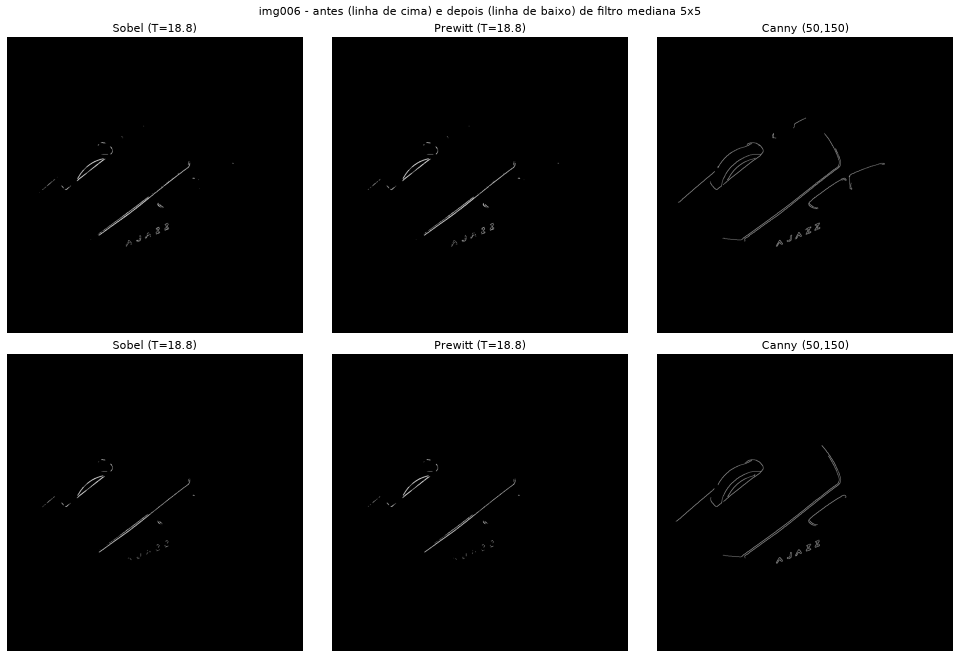

img006_original
operador                      pixels de borda  bordas falsas (%)  cobertura (%)  comprimento medio
Sobel (T=7.5)     original              14202               0.00           86.7              118.3
Sobel (T=7.5)     suavizada             12303               0.00           82.2              178.3
Prewitt (T=7.5)   original              14159               0.00           86.0              125.3
Prewitt (T=7.5)   suavizada             12316               0.00           81.7              189.5
Canny (20,60)     original               7698               0.00           84.1               68.7
Canny (20,60)     suavizada              6732               0.00           81.7              108.6
Sobel (T=18.8)    original               2620               0.00           30.3               31.6
Sobel (T=18.8)    suavizada              1983               0.00           25.0               39.7
Prewitt (T=18.8)  original               2527               0.00           29.4              

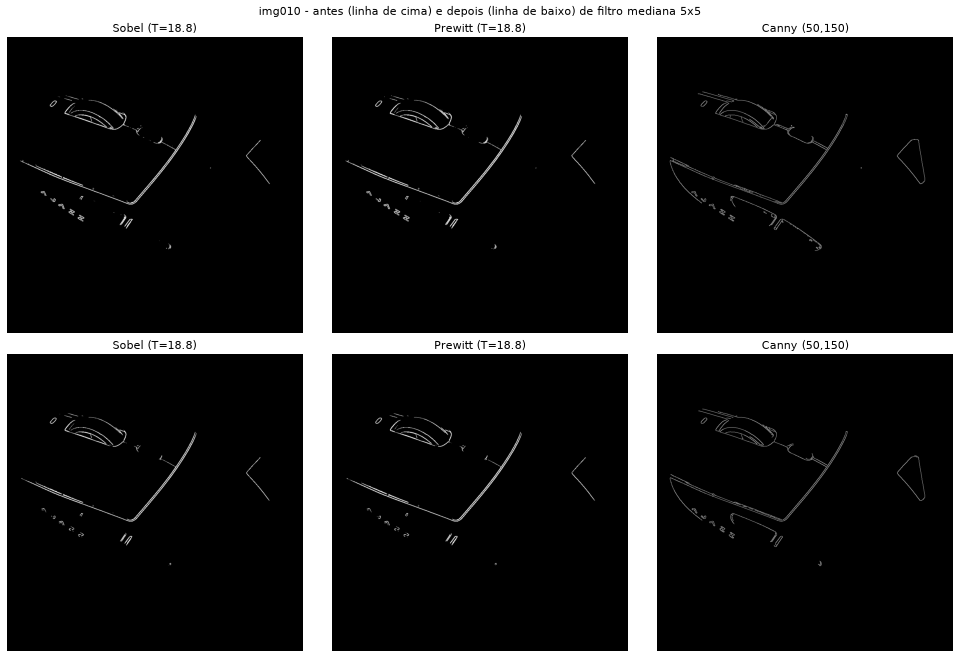

img010_original
operador                      pixels de borda  bordas falsas (%)  cobertura (%)  comprimento medio
Sobel (T=7.5)     original              19672               0.00           98.5               92.4
Sobel (T=7.5)     suavizada             16860               0.00           97.3              213.4
Prewitt (T=7.5)   original              19706               0.00           98.4              108.3
Prewitt (T=7.5)   suavizada             17065               0.00           97.0              258.6
Canny (20,60)     original              11844               0.00           91.6               79.0
Canny (20,60)     suavizada              8957               0.00           90.8              119.4
Sobel (T=18.8)    original               7497               0.00           66.8              122.9
Sobel (T=18.8)    suavizada              6437               0.00           62.3              119.2
Prewitt (T=18.8)  original               7607               0.00           66.2              

In [16]:
for nome, img in imagens.items():
    fig, axs = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
    fig.suptitle(f"{nome[:6]} - antes (linha de cima) e depois (linha de baixo) de {FILTRO_ESCOLHIDO}")
    for linha, mapas in enumerate((bordas_originais[nome], bordas_suavizadas[nome])):
        for ax, operador in zip(axs[linha], ("Sobel (T=18.8)", "Prewitt (T=18.8)", "Canny (50,150)")):
            ax.set_title(operador)
            ax.imshow(mapas[operador], cmap="gray")
            ax.axis("off")
    plt.show()

    plano, borda = regioes[nome]
    print(nome)
    print(f"{'operador':18s}{'':10s}{'pixels de borda':>17s}{'bordas falsas (%)':>19s}{'cobertura (%)':>15s}{'comprimento medio':>19s}")
    for operador in bordas_originais[nome]:
        for rotulo, mapas in (("original", bordas_originais[nome]), ("suavizada", bordas_suavizadas[nome])):
            n, falsas, cobertura, comp = metricas_bordas(mapas[operador], plano, borda)
            print(f"{operador:18s}{rotulo:10s}{n:17d}{falsas:19.2f}{cobertura:15.1f}{comp:19.1f}")
    print()

In [17]:
# media das 4 imagens: antes (original) -> depois (suavizada)
print(f"{'operador':18s}{'pixels de borda':>17s}{'bordas falsas (%)':>24s}{'cobertura (%)':>20s}{'comprimento medio':>22s}")
for operador in bordas_originais["img001_original"]:
    antes = np.mean([metricas_bordas(bordas_originais[n][operador], *regioes[n]) for n in imagens], axis=0)
    depois = np.mean([metricas_bordas(bordas_suavizadas[n][operador], *regioes[n]) for n in imagens], axis=0)
    print(f"{operador:18s}{100 * (depois[0] / antes[0] - 1):16.1f}%"
          f"{antes[1]:12.3f} ->{depois[1]:7.3f}{antes[2]:11.1f} ->{depois[2]:6.1f}{antes[3]:13.1f} ->{depois[3]:6.1f}")

operador            pixels de borda       bordas falsas (%)       cobertura (%)     comprimento medio
Sobel (T=7.5)                -35.4%       0.185 ->  0.016       96.3 ->  94.5         61.9 -> 139.8


Prewitt (T=7.5)              -33.1%       0.141 ->  0.015       96.1 ->  94.2         68.6 -> 155.4
Canny (20,60)                -66.0%       1.566 ->  0.052       93.0 ->  91.2         53.4 ->  79.3


Sobel (T=18.8)               -29.7%       0.004 ->  0.000       64.6 ->  56.9         50.4 ->  69.0
Prewitt (T=18.8)             -28.7%       0.004 ->  0.000       63.9 ->  56.1         56.2 ->  73.1
Canny (50,150)               -46.4%       0.019 ->  0.004       76.9 ->  69.8        137.6 -> 177.4


Sobel (T=25.0)               -30.0%       0.002 ->  0.000       52.8 ->  44.7         29.0 ->  38.5


Prewitt (T=25.0)             -28.9%       0.001 ->  0.000       51.7 ->  43.3         28.8 ->  44.8
Canny (100,200)              -35.0%       0.004 ->  0.001       61.2 ->  53.7        105.4 -> 134.4


### Sintese da Parte 4

Media das 4 imagens, antes -> depois da mediana 5x5:

| Operador | Pixels de borda | Bordas falsas (%) | Cobertura (%) | Comprimento medio (px) |
|---|---|---|---|---|
| Sobel (T=7,5) | -35,4% | 0,185 -> 0,016 | 96,3 -> 94,5 | 61,9 -> 139,8 |
| Prewitt (T=7,5) | -33,1% | 0,141 -> 0,015 | 96,1 -> 94,2 | 68,6 -> 155,4 |
| Canny (20,60) | -66,0% | 1,566 -> 0,052 | 93,0 -> 91,2 | 53,4 -> 79,3 |
| Sobel (T=18,8) | -29,7% | 0,004 -> 0,000 | 64,6 -> 56,9 | 50,4 -> 69,0 |
| Prewitt (T=18,8) | -28,7% | 0,004 -> 0,000 | 63,9 -> 56,1 | 56,2 -> 73,1 |
| Canny (50,150) | -46,4% | 0,019 -> 0,004 | 76,9 -> 69,8 | 137,6 -> 177,4 |
| Sobel (T=25) | -30,0% | 0,002 -> 0,000 | 52,8 -> 44,7 | 29,0 -> 38,5 |
| Prewitt (T=25) | -28,9% | 0,001 -> 0,000 | 51,7 -> 43,3 | 28,8 -> 44,8 |
| Canny (100,200) | -35,0% | 0,004 -> 0,001 | 61,2 -> 53,7 | 105,4 -> 134,4 |

**Quantidade de bordas detectadas.** Caiu de 29% a 66% em todos os operadores. A maior queda e a do Canny (20,60), que na imagem original estava detectando ruido.

**Reducao de bordas falsas.** Foi a melhoria mais clara: nos niveis sensiveis, as bordas falsas cairam cerca de 90% (Sobel 0,185 -> 0,016; Prewitt 0,141 -> 0,015) e 97% no Canny (1,566 -> 0,052). Nos niveis mais seletivos ja eram praticamente zero antes de filtrar.

**Continuidade das bordas reais.** Melhorou em todos os operadores e niveis: o comprimento medio dos segmentos mais que dobrou no Sobel e no Prewitt com T=7,5 (62 -> 140 px e 69 -> 155 px), pois o ruido deixa de quebrar as bordas em pedacos. Houve um custo: a **cobertura** das bordas reais caiu cerca de 2 pontos nos niveis sensiveis e cerca de 7 a 8 pontos nos niveis intermediario e seletivo. Isso acontece porque os limiares foram mantidos fixos e as bordas de baixo contraste e os detalhes finos eliminados pela mediana 5x5 deixam de passar do limiar. Uma melhoria possivel e reduzir um pouco os limiares depois de suavizar.

**A suavizacao melhorou a deteccao?** Sim em precisao e continuidade (menos falsas bordas, bordas mais continuas), com uma perda pequena de cobertura. Onde isso mais importa e no Canny sensivel: sem suavizacao ele e inutilizavel nas imagens ruidosas (4,63% de bordas falsas em img003); com mediana 5x5 passa a 0,21% mantendo 96,3% de cobertura.

**Qual operador foi mais robusto ao ruido?** Sem suavizar, **Sobel e Prewitt** (empatados) foram mais robustos que o Canny no nivel sensivel, pelos motivos da Parte 3 (o `cv2.Canny` nao suaviza internamente). Nos niveis intermediarios, o **Canny (50,150)** foi o melhor compromisso: falsas bordas praticamente nulas (0,019%) e maior cobertura (76,9% contra 64,6% do Sobel no mesmo nivel). Depois da suavizacao, os tres ficam robustos (em media, menos de 0,06% de falsas bordas em qualquer nivel).

**Qual apresentou melhor definicao estrutural?** O **Canny**: bordas finas (1 pixel) e segmentos mais longos (177 px de comprimento medio no nivel (50,150) apos suavizar, contra 69 px do Sobel e 73 px do Prewitt no nivel equivalente). Sobel e Prewitt produzem bordas grossas e mais fragmentadas.

## Conclusao

**Resumo do pipeline.** Selecionamos as imagens mais ruidosas de cada classe (ISO 3200 em img001 e img003 da classe A; img006 e img010 da classe B, de menor ruido mas com baixo contraste ou iluminacao irregular), comparamos seis filtros de suavizacao com metricas objetivas (ruido removido, bordas retidas, media e variancia) e avaliamos Sobel, Prewitt e Canny antes e depois do filtro escolhido (mediana 5x5).

**Principais conclusoes**
1. **Nao existe filtro que remova ruido sem custo.** Quanto mais ruido removido, mais borda perdida (grafico da Parte 2). A mediana 5x5 foi o melhor compromisso (71,7% do ruido removido, 87,2% das bordas retidas) por ser nao linear e preservar degraus, enquanto o Gaussiano sigma=3 removeu mais ruido (84,7%) mas destruiu quase metade das bordas.
2. **A variancia global quase nao muda** (queda de menos de 5% nas imagens de alto contraste e de ate ~12% nas de baixo contraste, no caso mais forte, sigma=3), porque a variancia e dominada pela estrutura da cena. O ruido so fica evidente medindo em regioes planas.
3. **O detector de bordas deve ser escolhido junto com o pre-processamento.** O Canny do OpenCV nao suaviza internamente: sem filtro previo e com limiar baixo ele detectou ruido (4,63% de falsas bordas em img003). Com mediana 5x5 as falsas bordas caem 90% a 97% e as bordas ficam mais continuas.
4. **Para uma tarefa de classificacao (por exemplo, controle x mouse)** que dependa de contornos, a combinacao recomendada neste dataset e **mediana 5x5 + Canny com limiares intermediarios (50,150)**: bordas finas e continuas, sem ruido, e maior cobertura que Sobel/Prewitt nos niveis intermediario e seletivo. Sobel/Prewitt continuam validos quando bordas grossas e magnitude do gradiente sao suficientes e o custo computacional importa.

**Limitacoes**
- Apenas 4 imagens, uma captura por cena, sem imagem "limpa" de referencia: o ruido e as bordas "falsas" e "reais" foram estimados por heuristicas (regioes planas e bordas fortes da imagem suavizada), nao por um ground truth. Sao boas para comparar filtros entre si, nao valores absolutos.
- Imagens reduzidas para 1024x1024 por recorte central: a reducao ja atenua parte do ruido (principalmente nas fotos de 3024 e 4160 px) e o recorte descarta as bordas da foto.
- Limiares de Sobel/Prewitt/Canny fixos para todas as imagens; o ideal seria adapta-los ao contraste de cada imagem (img006 tem variancia 165 e perde muita cobertura em limiares altos).
- A mediana 5x5 pode apagar detalhes finos, algo que a metrica de bordas retidas nao captura totalmente.

**Referencias**
- E-book *Pre-Processamento Basico de Imagens* (Unidade 2, Capitulo 1), Prof. Alyson Bezerra: filtros de media, Gaussiano e mediana (secoes 5.2.1 a 5.2.3, Tabela 1), operadores de Sobel, Prewitt e Canny (secao 5.2.4, Tabela 2).
- GONZALEZ, R. C.; WOODS, R. E. *Processamento digital de imagens*. 4. ed. Sao Paulo: Pearson, 2018.
- Documentacao do OpenCV: `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur`, `cv2.Sobel`, `cv2.filter2D`, `cv2.Canny`.